In [1]:
## conda : plot_python
import pandas as pd
import matplotlib.pyplot as plt
import glob 
import seaborn as sns
import numpy as np
from adjustText import adjust_text

plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

## Mimic PofTools

In [17]:
idmr= pd.read_csv("/path/to/project/pooch/findings/Imprinted_DMR_List_V1.LiftedOverToT2T-CHM13v2Hs1.tsv", sep="\t", header = 0)
idmr.head(2)

,Chromosome,Start,End,Methylated_allele,Name,Reference
0,chr1,11044370,11044544,Maternal,PTCHD2,Hernandez
1,chr1,21120031,21120143,Maternal,ECE1;LOC100506801,Hernandez


In [18]:
swapSamples= ["HG03579", "HG02717", "HG02451"]

In [19]:
files = glob.glob(f"/path/to/project/pooch/pooch_data/04.methyl_chm13/within_known_iDMRs/*bed")


df = pd.DataFrame()
for file in files:
    # print(file)
    sample=file.split("/")[-1].split("-")[2]
    hap=file.split("/")[-1].split(".")[-3]
    df_tmp = pd.read_csv(file, sep="\t", header=None)
    df_tmp["sample"] = sample
    df_tmp["hap"] = hap
    df = pd.concat([df, df_tmp], ignore_index=True)

df.columns = ["chr", "start", "end", "cov", "methylated", "sample", "hap"]
df.head()

,chr,start,end,cov,methylated,sample,hap
0,chr1,11044377,11044378,34,26,HG00621,hap1
1,chr1,11044412,11044413,25,18,HG00621,hap1
2,chr1,11044419,11044420,32,26,HG00621,hap1
3,chr1,11044423,11044424,34,26,HG00621,hap1
4,chr1,11044425,11044426,26,18,HG00621,hap1


In [20]:
df[['chr','sample']].drop_duplicates().groupby('chr').size().reset_index(name='count').sort_values('count', ascending=False)

,chr,count
0,chr1,123
1,chr10,123
2,chr11,123
3,chr12,123
4,chr13,123
5,chr14,123
6,chr15,123
7,chr16,123
8,chr17,123
9,chr18,123


In [21]:
df_wide = df.pivot_table(index=["chr", "start", "end"], columns=["sample", "hap"], values=["methylated",'cov']).reset_index()

In [22]:
idmr.head(2)

,Chromosome,Start,End,Methylated_allele,Name,Reference
0,chr1,11044370,11044544,Maternal,PTCHD2,Hernandez
1,chr1,21120031,21120143,Maternal,ECE1;LOC100506801,Hernandez


In [23]:
# how to index multiindex columns
from pandas.core.dtypes.missing import isna
import tqdm
hprc_hap_assign = []

for sample in tqdm.tqdm(df['sample'].unique()):
    for chr in idmr['Chromosome'].unique():
        hap_assign = []

        idmr_chr = idmr.loc[idmr['Chromosome'] == chr].copy()
        for start, end, hap in zip(idmr_chr['Start'], idmr_chr['End'], idmr_chr['Methylated_allele']):
            idmr_id = f"{chr}:{start}-{end}"
            df_wide_idmr = df_wide.loc[(df_wide['chr'] == chr) & (df_wide['start'] >= start) & (df_wide['end'] <= end)].copy()

            hap1_methyl = df_wide_idmr[('methylated', sample, 'hap1')]
            hap2_methyl = df_wide_idmr[('methylated', sample, 'hap2')]
            hap1_cov = df_wide_idmr[('cov', sample, 'hap1')]
            hap2_cov = df_wide_idmr[('cov', sample, 'hap2')]
            n_hap1 = sum(~isna(hap1_methyl))
            n_hap2 = sum(~isna(hap2_methyl))

            if ( n_hap1 < 11 or n_hap2 < 11 ) : 
                continue
            
            a_hap1 = df_wide_idmr.loc[hap1_methyl - hap2_methyl > 0.35,].shape[0]
            a_hap2 = df_wide_idmr.loc[hap2_methyl - hap1_methyl > 0.35,].shape[0]

            if ( n_hap1 > 11 or n_hap2 > 11 ) and (abs(a_hap1 - a_hap2)/n_hap1 > 0.1) and (abs(a_hap1 - a_hap2)/n_hap2 > 0.1):

                avg_met1 = np.mean(hap1_methyl / hap1_cov)
                avg_met2 = np.mean(hap2_methyl / hap2_cov)

                x_hap1 = avg_met1 * a_hap1 / n_hap1
                x_hap2 = avg_met2 * a_hap2 / n_hap2

                # print(f"{idmr_id} x_hap1 : {x_hap1}, x_hap2 : {x_hap2}")
                hap_assign.append({
                    'idmr_id': idmr_id,
                    'haplotype' : hap,
                    'x_hap1': x_hap1,
                    'x_hap2': x_hap2
                })
            else :
                # print(f"{idmr_id} not filtered")
                continue

        hap_assign = pd.DataFrame(hap_assign)
        
        # Skip if no regions passed filtering criteria
        if hap_assign.empty:
            continue
        
        hap1_maternal = hap_assign.loc[hap_assign['haplotype'] == 'Maternal','x_hap1'].sum()
        hap2_maternal = hap_assign.loc[hap_assign['haplotype'] == 'Maternal','x_hap2'].sum()
        hap1_paternal = hap_assign.loc[hap_assign['haplotype'] == 'Paternal','x_hap1'].sum()
        hap2_paternal = hap_assign.loc[hap_assign['haplotype'] == 'Paternal','x_hap2'].sum()

        confidence_score_hap1 = (hap1_maternal) / (hap1_maternal + hap1_paternal)
        confidence_score_hap2 = (hap2_maternal) / (hap2_maternal + hap2_paternal)

        if (hap1_maternal > hap2_maternal) :
            # print(f"hap1 is maternal, hap2 is paternal")
            hprc_hap_assign.append({
                'sample': sample,
                'chr' : chr,
                'maternal': 'hap1',
                'paternal': 'hap2',
                'confidence_score_hap1': confidence_score_hap1,
                'confidence_score_hap2': confidence_score_hap2,
                'hap1_maternal': hap1_maternal,
                'hap1_paternal': hap1_paternal,
                'hap2_maternal': hap2_maternal,
                'hap2_paternal': hap2_paternal
            })
        else:
            # print(f"hap2 is maternal, hap1 is paternal")
            hprc_hap_assign.append({
                'sample': sample,
                'chr' : chr,
                'maternal': 'hap2',
                'paternal': 'hap1',
                'confidence_score_hap2': confidence_score_hap1,
                'confidence_score_hap1': confidence_score_hap2,
                'hap1_maternal': hap1_maternal,
                'hap1_paternal': hap1_paternal,
                'hap2_maternal': hap2_maternal,
                'hap2_paternal': hap2_paternal
            })
            
hprc_hap_assign = pd.DataFrame(hprc_hap_assign)
hprc_hap_assign


  0%|          | 0/123 [00:00<?, ?it/s]/tmp/ipykernel_3336770/2969376576.py:58: RuntimeWarning: invalid value encountered in scalar divide
  confidence_score_hap1 = (hap1_maternal) / (hap1_maternal + hap1_paternal)
  4%|▍         | 5/123 [00:04<01:37,  1.21it/s]/tmp/ipykernel_3336770/2969376576.py:58: RuntimeWarning: invalid value encountered in scalar divide
  confidence_score_hap1 = (hap1_maternal) / (hap1_maternal + hap1_paternal)
  7%|▋         | 8/123 [00:06<01:34,  1.22it/s]/tmp/ipykernel_3336770/2969376576.py:58: RuntimeWarning: invalid value encountered in scalar divide
  confidence_score_hap1 = (hap1_maternal) / (hap1_maternal + hap1_paternal)
 14%|█▍        | 17/123 [00:13<01:27,  1.22it/s]/tmp/ipykernel_3336770/2969376576.py:58: RuntimeWarning: invalid value encountered in scalar divide
  confidence_score_hap1 = (hap1_maternal) / (hap1_maternal + hap1_paternal)
 15%|█▌        | 19/123 [00:15<01:25,  1.22it/s]/tmp/ipykernel_3336770/2969376576.py:58: RuntimeWarning: invalid va

,sample,chr,maternal,paternal,confidence_score_hap2,confidence_score_hap1,hap1_maternal,hap1_paternal,hap2_maternal,hap2_paternal
0,HG00621,chr1,hap2,hap1,1.000000,1.000000,0.389317,0.000000,3.239240,0.000000
1,HG00621,chr10,hap1,hap2,1.000000,1.000000,1.613471,0.000000,1.580733,0.000000
2,HG00621,chr11,hap2,hap1,0.084070,0.992774,0.195726,2.132420,2.218994,0.016151
3,HG00621,chr12,hap2,hap1,0.831061,0.971363,0.975038,0.198207,1.404507,0.041406
4,HG00621,chr13,hap2,hap1,1.000000,0.800261,0.386828,0.000000,3.516887,0.877790
...,...,...,...,...,...,...,...,...,...,...
2695,HG00558,chr5,hap2,hap1,1.000000,1.000000,0.329296,0.000000,1.841270,0.000000
2696,HG00558,chr6,hap2,hap1,0.922943,0.865021,1.028747,0.085891,3.445263,0.537602
2697,HG00558,chr7,hap2,hap1,1.000000,1.000000,0.582193,0.000000,5.962114,0.000000
2698,HG00558,chr8,hap2,hap1,1.000000,1.000000,0.630787,0.000000,5.314166,0.000000


In [24]:
hprc_hap_assign.groupby('chr').size().reset_index(name='count')

,chr,count
0,chr1,123
1,chr10,123
2,chr11,123
3,chr12,122
4,chr13,123
5,chr14,123
6,chr15,123
7,chr16,123
8,chr17,118
9,chr18,123


In [35]:
mode = "models_selection_using_fdr"

files = glob.glob(f"/path/to/project/pooch//pooch_data/07.{mode}/elastic*csv")

model_df = pd.DataFrame()
for file in files:
    model_df_tmp = pd.read_csv(file, header = 0, sep =',')
    model_df_tmp['chr'] = file.split('/')[-1].split('_')[-1].split('.')[-2]
    model_df = pd.concat([model_df, model_df_tmp])

model_df[True] = model_df['Test_Accuracy'] * 100
model_df = model_df[['chr',True]]
model_df[False] = 100 - model_df[True]
model_df = model_df.loc[model_df['chr'] != 'chrX']
model_df = model_df[['chr',False, True]]
model_df['chr'] = pd.Categorical(model_df['chr'], ordered = True, categories=[ f"chr{x}" for x in range(0,23)])
model_df = model_df.sort_values(by = "chr")
model_df

,chr,False,True
0,chr1,0.000000,100.000000
0,chr2,0.000000,100.000000
0,chr3,4.651163,95.348837
0,chr4,0.000000,100.000000
0,chr5,0.000000,100.000000
0,chr6,0.000000,100.000000
0,chr7,0.000000,100.000000
0,chr8,0.000000,100.000000
0,chr9,0.000000,100.000000
0,chr10,0.000000,100.000000


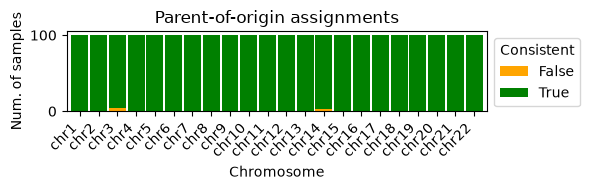

In [37]:
ax = model_df.plot(kind='bar', stacked=True, figsize=(6, 2), width=.9, color = {'Ambiguous' : 'grey', False : "orange", True : "green"})
ax.set_xlabel('Chromosome')
ax.set_ylabel('Num. of samples')
ax.set_title('Parent-of-origin assignments')
ax.set_xticklabels(model_df['chr'], rotation=45, ha='right')
# legend outside
ax.legend(title='Consistent', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

# plt.savefig('/data/Phillippy/projects/pooch_snakemake/figures/parent_of_origin_assignments_hprc_122_usingiDMRs.usingPooch.pdf', bbox_inches='tight')
plt.show()

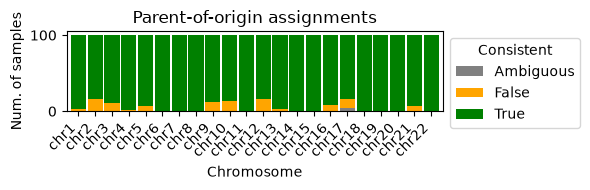

In [38]:
hprc_hap_assign['correct'] = True
hprc_hap_assign.loc[~hprc_hap_assign['sample'].isin(swapSamples) & (hprc_hap_assign['maternal'] == 'hap1'), "correct"] = False
hprc_hap_assign_count = hprc_hap_assign.groupby(['chr', 'correct']).size().reset_index(name='count')
hprc_hap_assign_count['chr'] = pd.Categorical(hprc_hap_assign_count['chr'], categories=[f'chr{i}' for i in range(1, 23)], ordered=True)

import matplotlib.pyplot as plt
hprc_hap_assign_count_pivot = hprc_hap_assign_count.pivot(index='chr', columns='correct', values='count').fillna(0)
hprc_hap_assign_count_pivot['Ambiguous'] = 123 - hprc_hap_assign_count_pivot[False] - hprc_hap_assign_count_pivot[True]
hprc_hap_assign_count_pivot = hprc_hap_assign_count_pivot[['Ambiguous', False, True]]
hprc_hap_assign_count_pivot['Ambiguous'] = hprc_hap_assign_count_pivot['Ambiguous']/123*100
hprc_hap_assign_count_pivot[True] = hprc_hap_assign_count_pivot[True]/123*100
hprc_hap_assign_count_pivot[False] = hprc_hap_assign_count_pivot[False]/123*100
ax = hprc_hap_assign_count_pivot.plot(kind='bar', stacked=True, figsize=(6, 2), width=.9, color = {'Ambiguous' : 'grey', False : "orange", True : "green"})
ax.set_xlabel('Chromosome')
ax.set_ylabel('Num. of samples')
ax.set_title('Parent-of-origin assignments')
ax.set_xticklabels(hprc_hap_assign_count_pivot.index, rotation=45, ha='right')
# legend outside
ax.legend(title='Consistent', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

# plt.savefig('/data/Phillippy/projects/pooch_snakemake/figures/parent_of_origin_assignments_hprc_122_usingiDMRs.usingPof.pdf', bbox_inches='tight')
plt.show()


In [39]:
hprc_hap_assign_count_pivot[False].sum()

np.float64(108.9430894308943)

In [40]:
hprc_hap_assign_count_pivot['Ambiguous'].sum()

np.float64(4.878048780487805)

In [41]:
test_sample = pd.read_csv("/path/to/project/pooch/model_validation/model_juhyun/test_data/testSet.samplelist", header = None)[0]
test_sample = list(test_sample)
test_sample[0:10]

['HG002',
 'HG00408',
 'HG00558',
 'HG00597',
 'HG00733',
 'HG00738',
 'HG00741',
 'HG01071',
 'HG01106',
 'HG01175']

In [53]:
hprc_hap_assign.loc[hprc_hap_assign['sample'].isin(test_sample)]

,sample,chr,maternal,paternal,confidence_score_hap2,confidence_score_hap1,hap1_maternal,hap1_paternal,hap2_maternal,hap2_paternal,correct
66,HG02809,chr1,hap2,hap1,1.000000,1.000000,0.083624,0.000000,3.402847,0.000000,True
67,HG02809,chr10,hap2,hap1,1.000000,1.000000,1.175189,0.000000,1.656324,0.000000,True
68,HG02809,chr11,hap2,hap1,0.000000,0.987166,0.000000,2.077546,2.624154,0.034117,True
69,HG02809,chr12,hap2,hap1,0.885858,0.672604,0.108975,0.014041,1.164788,0.566970,True
70,HG02809,chr13,hap2,hap1,1.000000,0.725845,1.627871,0.000000,2.503070,0.945421,True
...,...,...,...,...,...,...,...,...,...,...,...
2695,HG00558,chr5,hap2,hap1,1.000000,1.000000,0.329296,0.000000,1.841270,0.000000,True
2696,HG00558,chr6,hap2,hap1,0.922943,0.865021,1.028747,0.085891,3.445263,0.537602,True
2697,HG00558,chr7,hap2,hap1,1.000000,1.000000,0.582193,0.000000,5.962114,0.000000,True
2698,HG00558,chr8,hap2,hap1,1.000000,1.000000,0.630787,0.000000,5.314166,0.000000,True


In [54]:
hprc_hap_assign_count

,chr,correct,count
0,chr1,False,2
1,chr1,True,41
2,chr10,False,4
3,chr10,True,39
4,chr11,True,43
5,chr12,False,4
6,chr12,True,38
7,chr13,False,1
8,chr13,True,42
9,chr14,True,43


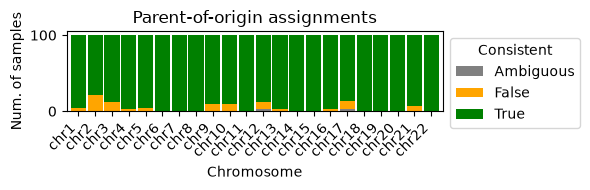

In [52]:
# hprc_hap_assign['correct'] = True
# hprc_hap_assign.loc[~hprc_hap_assign['sample'].isin(swapSamples) & (hprc_hap_assign['maternal'] == 'hap1'), "correct"] = False
hprc_hap_assign_count = hprc_hap_assign.loc[hprc_hap_assign['sample'].isin(test_sample)].groupby(['chr', 'correct']).size().reset_index(name='count')
hprc_hap_assign_count['chr'] = pd.Categorical(hprc_hap_assign_count['chr'], categories=[f'chr{i}' for i in range(1, 23)], ordered=True)

import matplotlib.pyplot as plt
hprc_hap_assign_count_pivot = hprc_hap_assign_count.pivot(index='chr', columns='correct', values='count').fillna(0)
hprc_hap_assign_count_pivot['Ambiguous'] = len(test_sample) - hprc_hap_assign_count_pivot[False] - hprc_hap_assign_count_pivot[True]
hprc_hap_assign_count_pivot = hprc_hap_assign_count_pivot[['Ambiguous', False, True]]
hprc_hap_assign_count_pivot['Ambiguous'] = hprc_hap_assign_count_pivot['Ambiguous']/len(test_sample)*100
hprc_hap_assign_count_pivot[True] = hprc_hap_assign_count_pivot[True]/len(test_sample)*100
hprc_hap_assign_count_pivot[False] = hprc_hap_assign_count_pivot[False]/len(test_sample)*100
ax = hprc_hap_assign_count_pivot.plot(kind='bar', stacked=True, figsize=(6, 2), width=.9, color = {'Ambiguous' : 'grey', False : "orange", True : "green"})
ax.set_xlabel('Chromosome')
ax.set_ylabel('Num. of samples')
ax.set_title('Parent-of-origin assignments')
ax.set_xticklabels(hprc_hap_assign_count_pivot.index, rotation=45, ha='right')
# legend outside
ax.legend(title='Consistent', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

plt.savefig('/path/to/project/pooch//figures/parent_of_origin_assignments_hprc_122_usingiDMRs.usingPof.43testsamples.pdf', bbox_inches='tight')
plt.show()

In [58]:
hprc_hap_assign_count_pivot = hprc_hap_assign_count.pivot(index='chr', columns='correct', values='count').fillna(0)
hprc_hap_assign_count_pivot['Ambiguous'] = len(test_sample) - hprc_hap_assign_count_pivot[False] - hprc_hap_assign_count_pivot[True]
hprc_hap_assign_count_pivot = hprc_hap_assign_count_pivot[['Ambiguous', False, True]]
hprc_hap_assign_count_pivot

correct,Ambiguous,False,True
chr,,,
chr1,0.0,2.0,41.0
chr2,0.0,9.0,34.0
chr3,0.0,5.0,38.0
chr4,0.0,1.0,42.0
chr5,0.0,2.0,41.0
chr6,0.0,0.0,43.0
chr7,0.0,0.0,43.0
chr8,0.0,0.0,43.0
chr9,0.0,4.0,39.0


In [64]:
sum(hprc_hap_assign_count_pivot['Ambiguous']) +  sum(hprc_hap_assign_count_pivot['Ambiguous']) + sum(hprc_hap_assign_count_pivot[False])

45.0

In [65]:
sum(hprc_hap_assign_count_pivot['Ambiguous'])

2.0

In [66]:
sum(hprc_hap_assign_count_pivot[True])

903.0

In [67]:
sum(hprc_hap_assign_count_pivot[False])

41.0

In [72]:
903/946 * 100

95.45454545454545